In [1]:
import json
import sys
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import numpy as np

REPO_ROOT = Path.cwd().parent
ANNOTATION_FOLDER = REPO_ROOT / "raw_data" / "annotation" / "threshold"
OUTPUT_FOLDER = REPO_ROOT / "methodology" / "output"
FIGURE_FOLDER = REPO_ROOT / "methodology" / "figures"

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from cscaf.figures import ThresholdCalibrationFigure
from cscaf.study import Study
from cscaf.calibration import AnnotatorAgreement, MinimumLength, Source, ThresholdCalibration

study = Study.from_config()
validation = study.section("threshold_validation")
settings = validation["analysis"]
seed = study.seed
print("seed     :", seed)
print("settings :", settings)

seed     : 42
settings : {'grid': {'min': 0.3, 'max': 0.8, 'step': 0.005}, 'bootstrap': 5000, 'confidence': 0.95, 'kappa_gate': 0.4, 'band_rate': 'mean_of_sources', 'fisher_alpha': 0.05, 'weight_step': 0.05}


In [2]:
def read(name):
    return json.loads((ANNOTATION_FOLDER / name).read_text(encoding="utf-8"))


key = read("key.json")
population = read("population.json")
labels = {name: read(f"{name}/annotation_{name}_labels.json") for name in validation["annotators"]}
adjudicated = read("consensus/annotation_consensus_labels.json")["labels"]
print("run      :", key["run_id"])
for name, document in labels.items():
    visible = sorted(pid for pid, entry in document["labels"].items() if entry.get("score_visible"))
    print(f"{name:8s} : {document['labeled']} of {document['total']} labelled, score shown for {len(visible)} {visible}")
print("consensus:", len(adjudicated), "pairs adjudicated")

run      : sat-12l-sm_all-mpnet-base-v2_414c4542
annotator_1 : 300 of 300 labelled, score shown for 0 []
annotator_2 : 300 of 300 labelled, score shown for 0 []
consensus: 21 pairs adjudicated


In [3]:
def length_group(words):
    for group in validation["length_groups"]:
        if group["min_words"] <= words and (group.get("max_words") is None or words <= group["max_words"]):
            return group["name"]
    raise ValueError(words)


pairs = []
for pair in key["pairs"]:
    first, second = (labels[name]["labels"][pair["pair_id"]]["label"] for name in validation["annotators"])
    consensus = first if first == second else adjudicated[pair["pair_id"]]["label"]
    words = len(pair["sentence"].split())
    pairs.append({"pair_id": pair["pair_id"], "source": pair["source"], "stratum": pair["stratum"],
                  "rf_sentence_id": pair["rf_sentence_id"], "similarity_score": pair["score"],
                  "words": words, "length_group": length_group(words),
                  "label_annotator_1": first, "label_annotator_2": second, "label_consensus": consensus})

disagreements = {p["pair_id"] for p in pairs if p["label_annotator_1"] != p["label_annotator_2"]}
assert disagreements == set(adjudicated), sorted(disagreements ^ set(adjudicated))
cells = {(c["stratum"], c["source"], c["length_group"]) for c in population["cells"]}
assert {(p["stratum"], p["source"], p["length_group"]) for p in pairs} <= cells
print(len(pairs), "pairs,", len(disagreements), "disagreements")

300 pairs, 21 disagreements


In [4]:
strata = {s["h"]: s for s in validation["strata"]}
by_stratum = Counter(p["stratum"] for p in pairs)
by_source = Counter(p["source"] for p in pairs)
transition = [h for h, s in strata.items() if s["min"] >= 0.45 and s["max"] <= 0.70]
per_statement = Counter(p["rf_sentence_id"] for p in pairs)
split = {}
for cell in population["cells"]:
    split.setdefault((cell["stratum"], cell["source"]), []).append(cell["sampled"])
sample = {
    "pairs": len(pairs),
    "by_source": dict(by_source),
    "strata": len(strata),
    "by_stratum": {h: by_stratum[h] for h in sorted(strata)},
    "planned_by_stratum": {h: s["n"] for h, s in sorted(strata.items())},
    "transition_range": [strata[transition[0]]["min"], strata[transition[-1]]["max"]],
    "transition_pairs": sum(by_stratum[h] for h in transition),
    "length_groups": len(validation["length_groups"]),
    "length_groups_equal": all(max(v) - min(v) <= 1 for v in split.values()),
    "statements": len(per_statement),
    "max_pairs_per_statement": max(per_statement.values()),
    "limit_per_statement": validation["limits"]["per_statement"],
    "population": sum(c["population"] for c in population["cells"]),
}
assert sample["by_stratum"] == sample["planned_by_stratum"]
sample

{'pairs': 300,
 'by_source': {'curriculum': 150, 'job_advertisement': 150},
 'strata': 9,
 'by_stratum': {1: 6, 2: 12, 3: 18, 4: 42, 5: 60, 6: 60, 7: 54, 8: 30, 9: 18},
 'planned_by_stratum': {1: 6,
  2: 12,
  3: 18,
  4: 42,
  5: 60,
  6: 60,
  7: 54,
  8: 30,
  9: 18},
 'transition_range': [0.45, 0.7],
 'transition_pairs': 216,
 'length_groups': 3,
 'length_groups_equal': True,
 'statements': 132,
 'max_pairs_per_statement': 3,
 'limit_per_statement': 3,
 'population': 501637}

In [5]:
agreement = AnnotatorAgreement.report(pairs, settings["bootstrap"], settings["confidence"], seed, settings["kappa_gate"])
for group in ("overall", "curriculum", "job_advertisement"):
    a = agreement[group]
    print(f"{group:18s} n {a['n']:3d}  kappa {a['kappa']:.3f} [{a['kappa_ci'][0]:.3f}, {a['kappa_ci'][1]:.3f}]  "
          f"agreement {a['agreement']:.3f}  agreed {round(a['agreement'] * a['n'])}")
print("gate passed:", agreement["gate_passed"])

overall            n 300  kappa 0.854 [0.790, 0.911]  agreement 0.930  agreed 279
curriculum         n 150  kappa 0.834 [0.739, 0.918]  agreement 0.920  agreed 138
job_advertisement  n 150  kappa 0.875 [0.788, 0.945]  agreement 0.940  agreed 141
gate passed: True


In [6]:
decision = MinimumLength(validation["minimum_length_rule"]).decide(pairs, population, settings, seed)
results = decision["results_final"]
comparison = decision["comparison"]
print(f"minimum length: 2 words {comparison['short_aligned']}/{comparison['short_n']} aligned above tau, "
      f"3+ words {comparison['longer_aligned']}/{comparison['longer_n']}; one-sided Fisher p = "
      f"{comparison['fisher_one_sided_p']:.4f} -> {comparison['decision']}: {comparison['minimum_words']} words")
print(f"tau = {results['tau']:.3f}  95% CI [{results['tau_ci'][0]:.3f}, {results['tau_ci'][1]:.3f}]  "
      f"objective {results['objective_at_tau']:.4f}")
print(f"tau in config.yaml: {study.tau}")

minimum length: 2 words 18/19 aligned above tau, 3+ words 85/96; one-sided Fisher p = 0.8987 -> keep the minimum unit length: 2 words
tau = 0.585  95% CI [0.580, 0.595]  objective 0.8918
tau in config.yaml: 0.585


In [7]:
rates = ThresholdCalibration.rates_by_stratum(results["strata"])
below = [h for h, s in strata.items() if s["max"] <= 0.60]
above = [h for h, s in strata.items() if s["min"] >= 0.60]
for h, r in rates.items():
    print(f"stratum {h} [{strata[h]['min']:.2f}, {strata[h]['max']:.2f})  {r['positives']:3d}/{r['n']:3d} = {r['rate']:.3f}")
drop_test = next(step for step in results["r3"]["steps"] if step["test"].startswith("drop"))
shares = {
    "max_share_below_0_60": max(rates[h]["rate"] for h in below),
    "min_share_from_0_60": min(rates[h]["rate"] for h in above),
    "partial_band_test": drop_test["test"],
    "partial_band_fisher_p": drop_test["p"],
    "bands": results["r3"]["bands"],
}
shares

stratum 1 [-1.00, 0.30)    0/  6 = 0.000
stratum 2 [0.30, 0.39)    0/ 12 = 0.000
stratum 3 [0.39, 0.45)    0/ 18 = 0.000
stratum 4 [0.45, 0.50)    2/ 42 = 0.048
stratum 5 [0.50, 0.55)    5/ 60 = 0.083
stratum 6 [0.55, 0.60)   16/ 60 = 0.267
stratum 7 [0.60, 0.70)   48/ 54 = 0.889
stratum 8 [0.70, 0.80)   28/ 30 = 0.933
stratum 9 [0.80, 1.01)   18/ 18 = 1.000


{'max_share_below_0_60': 0.26666666666666666,
 'min_share_from_0_60': 0.8888888888888888,
 'partial_band_test': 'drop [0.39, 0.585) against the pairs below 0.39',
 'partial_band_fisher_p': 0.22560451482817914,
 'bands': [{'min': 0.585, 'max': 1.01, 'w': 1.0},
  {'min': 0.39, 'max': 0.585, 'w': 0.0},
  {'min': -1.0, 'max': 0.39, 'w': 0.0}]}

In [8]:
tau = results["tau"]
calibration = ThresholdCalibration(pairs, population)
data = calibration.data
score, label, source, weight = (data[k] for k in ("score", "label", "source", "weight"))


def specificity(index):
    out = {}
    for s, name in enumerate(Source):
        members = index[source[index] == s]
        above_tau, positive, w = score[members] >= tau, label[members] == 1, weight[members]
        tn, fp = (w * (~above_tau & ~positive)).sum(), (w * (above_tau & ~positive)).sum()
        out[name] = float(tn / (tn + fp)) if tn + fp else float("nan")
    return out


point = specificity(np.arange(len(score)))
rng = np.random.default_rng(seed)
cell_index = calibration.cell_indices()
replicates = [specificity(np.concatenate([rng.choice(c, size=len(c), replace=True) for c in cell_index]))
              for _ in range(settings["bootstrap"])]
low, high = (1 - settings["confidence"]) / 2 * 100, (1 + settings["confidence"]) / 2 * 100

table_s2 = {}
for name in Source:
    members = [p for p in pairs if p["source"] == name]
    tp = sum(p["similarity_score"] >= tau and p["label_consensus"] == 1 for p in members)
    fp = sum(p["similarity_score"] >= tau and p["label_consensus"] == 0 for p in members)
    fn = sum(p["similarity_score"] < tau and p["label_consensus"] == 1 for p in members)
    table_s2[name] = {"pairs": len(members), "matching": tp + fn, "tp": tp, "fp": fp, "fn": fn,
                      "tn": len(members) - tp - fp - fn,
                      **results["weighted_metrics"][name],
                      "specificity": point[name],
                      "specificity_ci": [float(np.nanpercentile([r[name] for r in replicates], low)),
                                         float(np.nanpercentile([r[name] for r in replicates], high))]}
mean = results["weighted_metrics"]["mean_of_sources"]
table_s2["mean_of_sources"] = {
    **{k: sum(table_s2[name][k] for name in Source) for k in ("pairs", "matching", "tp", "fp", "fn", "tn")},
    **mean, "specificity": float(np.mean([point[name] for name in Source]))}

print(f"{'source':18s} {'pairs':>11s} {'TP/FP/FN/TN':>16s}  precision             recall                "
      f"specificity           F1")
for name, row in table_s2.items():
    cells_text = []
    for metric in ("precision", "recall", "specificity", "f1"):
        ci = row.get(f"{metric}_ci")
        cells_text.append(f"{row[metric]:.3f} [{ci[0]:.3f}, {ci[1]:.3f}]" if ci else f"{row[metric]:.3f}               ")
    print(f"{name:18s} {row['pairs']:4d} ({row['matching']:3d}) "
          f"{row['tp']:4d}/{row['fp']}/{row['fn']}/{row['tn']:<4d}  " + "  ".join(cells_text))
print(f"\nROC AUC over all {len(pairs)} pairs: {results['sample_metrics']['roc_auc']:.4f}")

source                   pairs      TP/FP/FN/TN  precision             recall                specificity           F1
curriculum          150 ( 59)   50/7/9/84    0.876 [0.741, 0.972]  0.897 [0.819, 0.968]  0.901 [0.809, 0.977]  0.887 [0.800, 0.947]
job_advertisement   150 ( 58)   53/5/5/87    0.962 [0.919, 0.995]  0.840 [0.660, 0.988]  0.994 [0.987, 0.999]  0.897 [0.780, 0.980]
mean_of_sources     300 (117)  103/12/14/171   0.919 [0.850, 0.972]  0.869 [0.771, 0.961]  0.947                 0.892 [0.821, 0.950]

ROC AUC over all 300 pairs: 0.9379


In [9]:
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
output = OUTPUT_FOLDER / "04_threshold_calibration.json"
record = {
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "paper_section": "3.4",
    "run": key["run_id"],
    "seed": seed,
    "settings": settings,
    "sample": sample,
    "agreement": agreement,
    "adjudicated": len(adjudicated),
    "shares": shares,
    "table_s2": table_s2,
    "minimum_length": comparison,
    **{k: results[k] for k in ("n_pairs", "tau", "tau_ci", "objective_at_tau", "curve", "sample_metrics",
                               "weighted_metrics", "strata", "r3")},
}
output.write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8")
print("written to", output.relative_to(REPO_ROOT))

figure = ThresholdCalibrationFigure(output, validation["strata"]).draw(
    FIGURE_FOLDER / "figure_2_threshold_calibration.png", with_strata=False)
print("figure    :", figure.relative_to(REPO_ROOT))

written to methodology\output\04_threshold_calibration.json


figure    : methodology\figures\figure_2_threshold_calibration.png


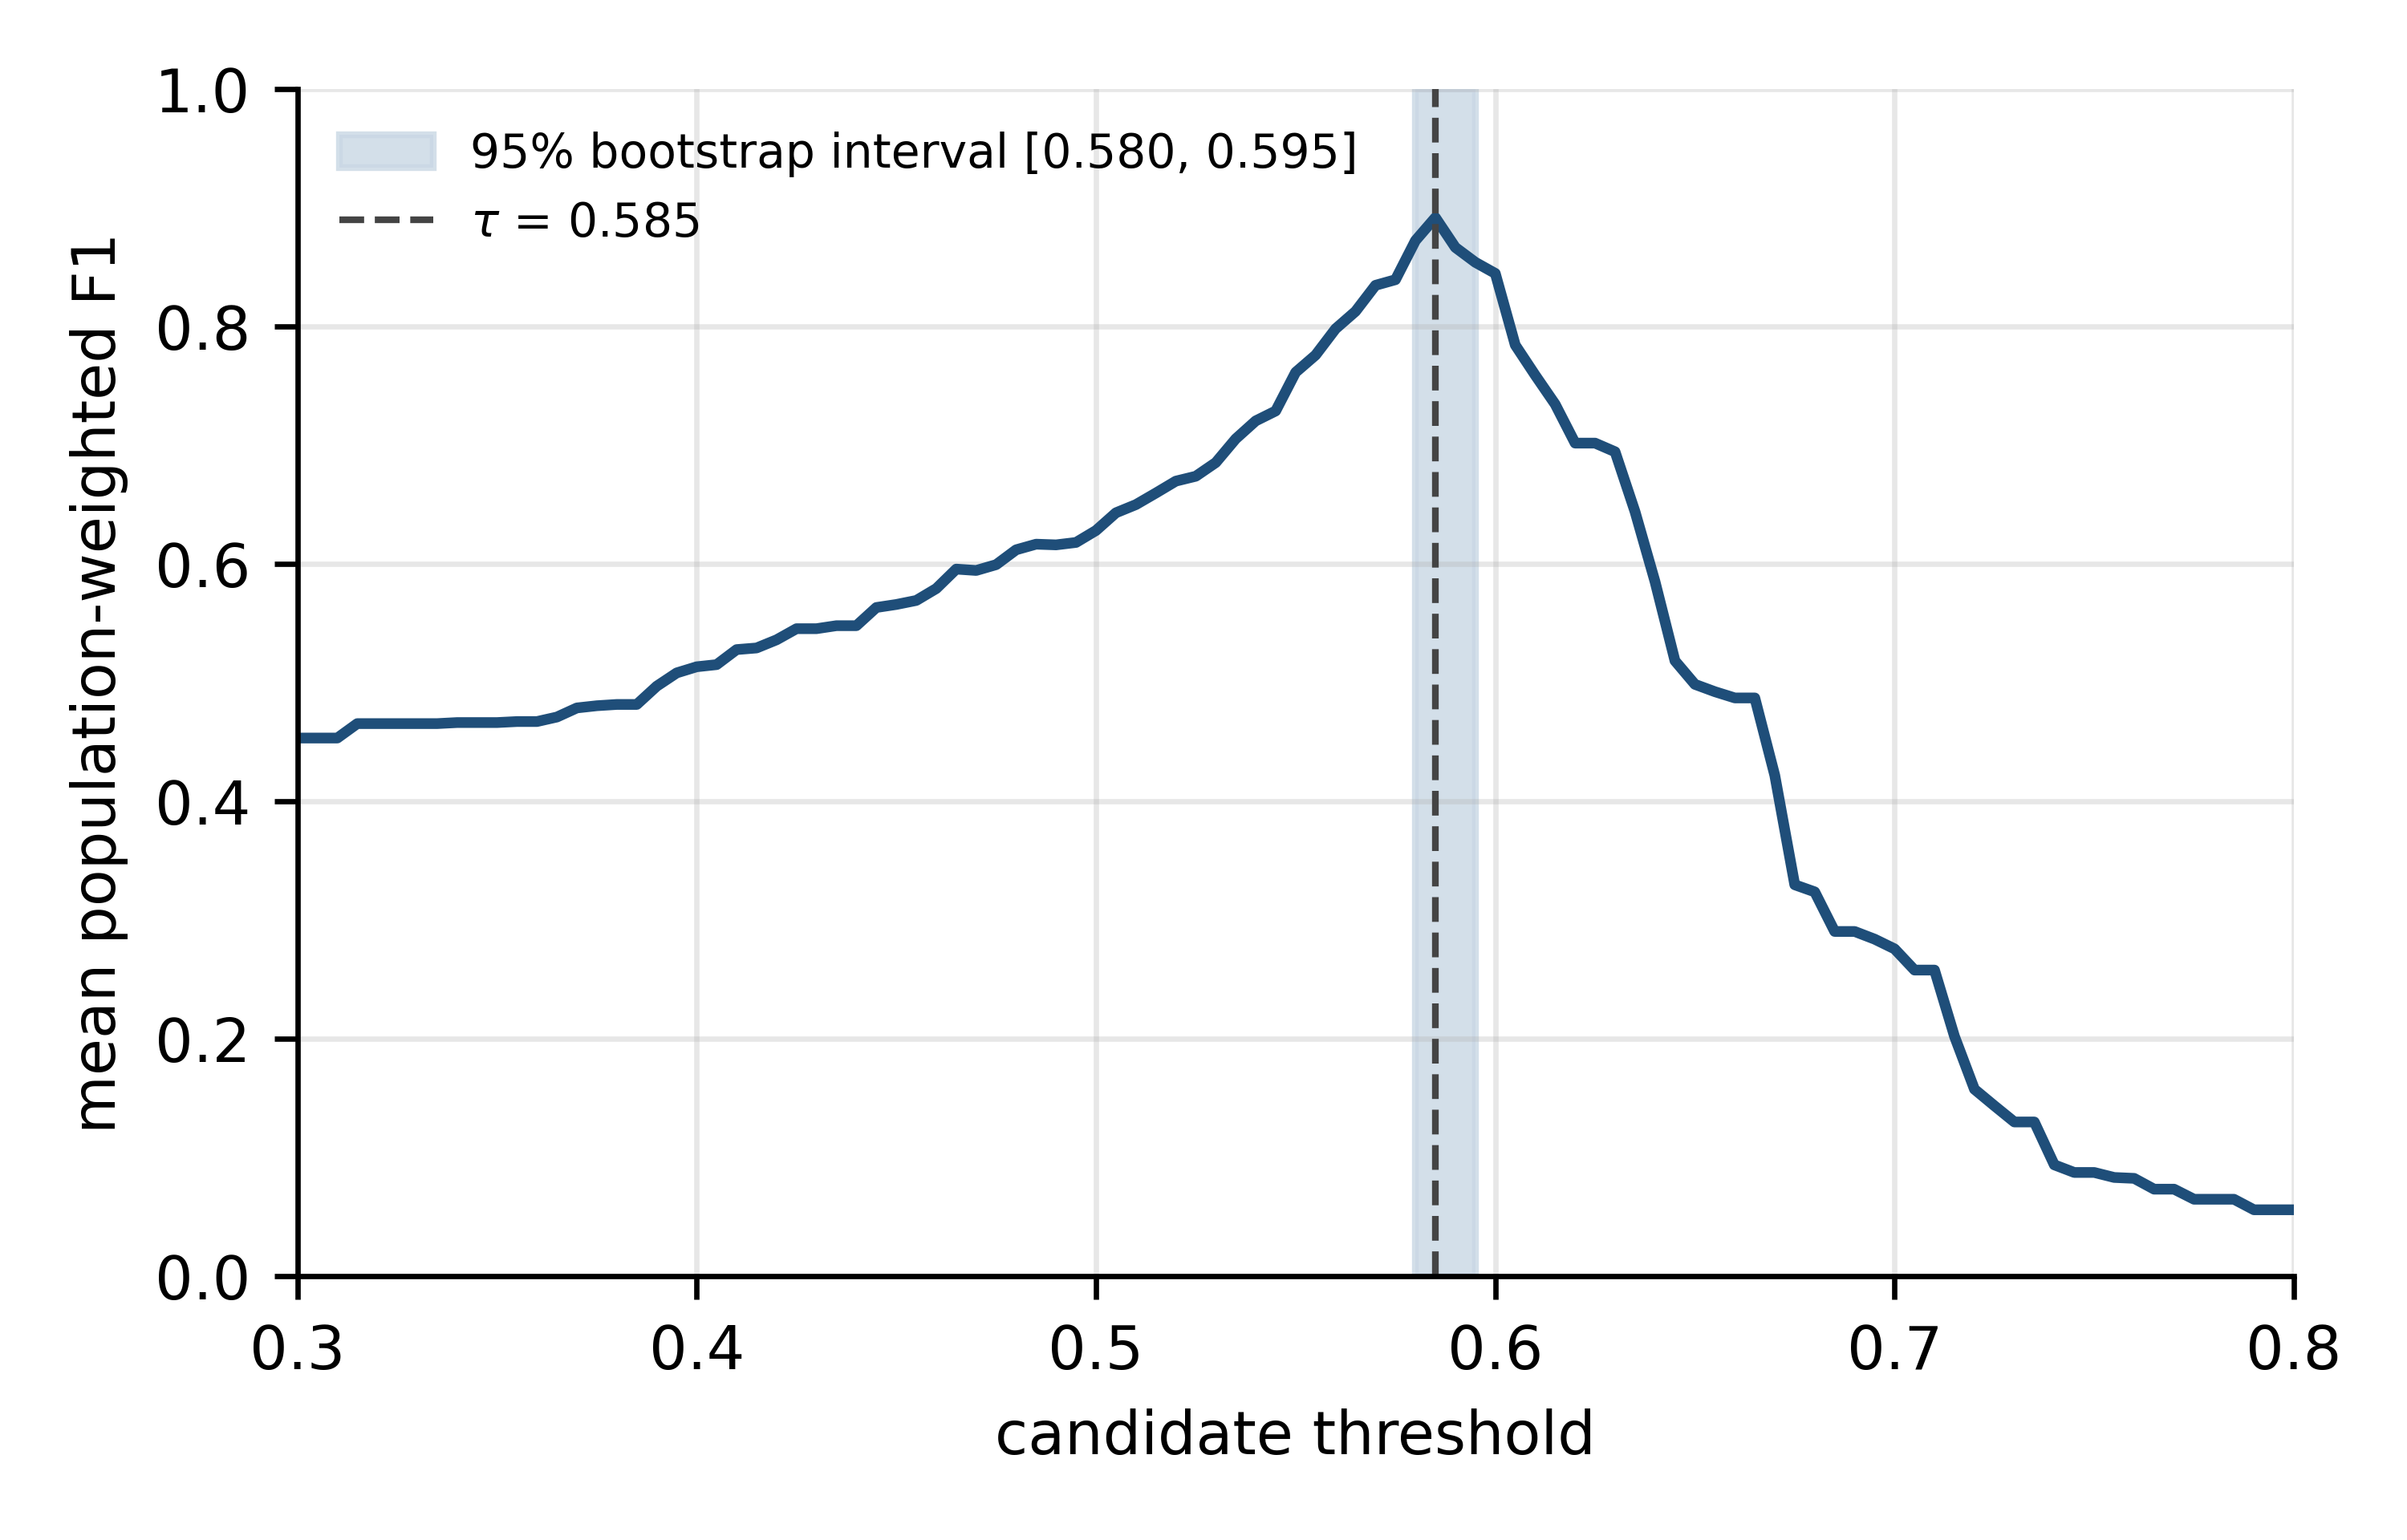

In [10]:
from IPython.display import Image

Image(filename=str(figure), width=600)